# Laptop Price Prediction System
**AIC354 Machine Learning Fundamentals - Assignment 3**

| | |
| --- | --- |
| **Student** | S.M.MATEEN UD DIN |
| **Registration No.** | FA24-BSE-152 |
| **University** | COMSATS University Islamabad, Lahore Campus |
| **Live web app** | _add your Streamlit link here after Step 11_ |

## Setup: Running This Notebook

### Option A: Google Colab
1. Open https://colab.research.google.com and sign in.
2. **File -> Upload notebook** and choose this `.ipynb` file.
3. **Runtime -> Run all**.
4. In **Step 2.1**, if `laptop_price.csv` is not found next to the notebook, a **Choose Files** button appears. Select `laptop_price.csv` from the project folder. (If you skip the upload and the runtime has internet, the notebook tries to download a public copy automatically.)

The whole notebook runs in about **2-4 minutes**.

### Option B: Jupyter on your own computer
```
python -m venv venv
venv\Scripts\activate            (Windows)   |   source venv/bin/activate   (macOS / Linux)
pip install -r requirements.txt
pip install matplotlib tqdm prettytable notebook ipykernel
jupyter notebook
```
Keep `laptop_price.csv` in the same folder as the notebook.

## Description
<p>
A Laptop Price Prediction System: a machine learning model that estimates the market price of a laptop (in euros) from its specifications such as brand, type, RAM, storage, processor, graphics card, screen and weight. Five regression algorithms are compared with <b>10-fold cross validation</b> on 1,303 laptops, and the best one is deployed as a web app.
</p>

## Introduction

##### **Definition** A regression ML task that predicts the price (EUR) of a laptop from its hardware specifications.
##### **Application** Price-checking tool for buyers (is this laptop over-priced?), pricing assistant for online shops and resellers, and a quick estimate when trading in a used laptop.

## Input and Output

### Inputs (Features / Attributes)

| **Input Feature** | **Description** | **Type** | **Example Values** |
| --- | --- | --- | --- |
| **Company** | Laptop brand | Categorical | Dell, HP, Lenovo, Asus, Apple ... |
| **TypeName** | Laptop category | Categorical | Notebook, Gaming, Ultrabook, 2 in 1 Convertible, Workstation, Netbook |
| **Inches** | Screen size | Numerical | 10.1 - 18.4 |
| **Ram_GB** | RAM size | Numerical | 2 - 64 |
| **Weight_kg** | Weight | Numerical | 0.7 - 4.7 |
| **ppi** | Screen sharpness (pixels per inch) | Numerical | about 100 - 350 |
| **Touchscreen** | Has a touchscreen? | Binary | 0, 1 |
| **IPS** | Has an IPS panel? | Binary | 0, 1 |
| **Cpu_Family** | Processor family | Categorical | Intel Core i3 / i5 / i7, Other Intel, AMD |
| **Cpu_GHz** | Processor clock speed | Numerical | 0.9 - 3.6 |
| **SSD_GB** | SSD capacity | Numerical | 0 - 1024 |
| **HDD_GB** | HDD capacity | Numerical | 0 - 2048 |
| **Other_Storage_GB** | Flash storage + hybrid drives | Numerical | 0 - 512 |
| **Gpu_Brand** | Graphics card maker | Categorical | Intel, Nvidia, AMD, ARM |
| **OS_Group** | Operating system group | Categorical | Windows, macOS, No OS, Linux / Chrome / Android |

### Output (Prediction)

| **Output Attribute** | **Description** | **Possible Values** |
| --- | --- | --- |
| **Price_euros** | Price of the laptop | about 174 - 6,099 EUR |

## Table of Content
- [Step 1: Import Libraries](#step-1)
- [Step 2: Load Sample Data](#step-2)
- [Step 3: Understand and Pre-process Sample Data](#step-3)
- [Step 4: Feature Extraction](#step-4)
- [Step 5: Build the Pre-processing Pipeline](#step-5)
- [Step 6: Training and Testing Phase (10-Fold Cross Validation)](#step-6)
- [Step 7: Evaluate and Compare the Algorithms](#step-7)
- [Step 8: Train and Save the Final Model](#step-8)
- [Step 9: Application Phase](#step-9)
- [Step 10: Feedback Phase](#step-10)
- [Step 11: Deploy as a Public Web App](#step-11)
- [Conclusion](#conclusion)

<a id="step-1"></a>

### Step 1: Import Libraries

In [1]:
"""
Purpose of this code:
----------------------
Imports the libraries used to load the data, build features, run 10-fold
cross validation for 5 regression algorithms, compare them and save the best.
"""
import os
import re
import time
import pickle
import urllib.request

import numpy as np
import pandas as pd

import sklearn
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor

# The 5 regression algorithms compared in this assignment
from sklearn.linear_model import Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor

import matplotlib
import matplotlib.pyplot as plt
from tqdm import tqdm
from prettytable import PrettyTable

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

print("Library Versions Used in This Run:")
print("==================================\n")
print(f"NumPy        : {np.__version__}")
print(f"Pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")

Library Versions Used in This Run:

NumPy        : 2.4.4
Pandas       : 3.0.2
scikit-learn : 1.8.0
Matplotlib   : 3.10.8


<a id="step-2"></a>

### Step 2: Load Sample Data

`laptop_price.csv` is a public laptop price dataset with **1,303 laptops** listed by online shops. Every row is one laptop model with its specifications (brand, type, screen, CPU, RAM, storage, GPU, operating system, weight) and its **price in euros**. Most columns are **text** (for example `"256GB SSD + 1TB HDD"`, `"Intel Core i5 7200U 2.5GHz"`), so the main work of this project is turning that text into useful numeric features (Step 4).

<a id="step-2-1"></a>

#### Step 2.1: Make Sure the Dataset File Is Available

In [2]:
"""
Purpose of this section:
-------------------------
Makes sure 'laptop_price.csv' is available.
1. If the file is already in the folder, it is used directly.
2. In Google Colab, a 'Choose Files' button asks you to upload it.
3. Otherwise a public copy of the dataset is downloaded.
"""
CSV_FILE = "laptop_price.csv"
BACKUP_URL = "https://raw.githubusercontent.com/Parhinder/Laptop-Price-Predictor-/main/laptop_price.csv"

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not os.path.exists(CSV_FILE) and IN_COLAB:
    print(f"Please click 'Choose Files' and select '{CSV_FILE}'")
    uploaded = files.upload()
    if uploaded:
        os.rename(list(uploaded.keys())[0], CSV_FILE)

if not os.path.exists(CSV_FILE):
    print(f"Downloading dataset from {BACKUP_URL} ...")
    urllib.request.urlretrieve(BACKUP_URL, CSV_FILE)

print(f"Using '{CSV_FILE}' ({os.path.getsize(CSV_FILE) / 1e3:,.0f} KB)")

Using 'laptop_price.csv' (197 KB)


<a id="step-2-2"></a>

#### Step 2.2: Load the Data

In [3]:
"""
Purpose of this section:
-------------------------
Loads the CSV into a pandas DataFrame and shows the first rows.
(The file uses Latin-1 encoding, so encoding="latin-1" is needed.)
"""
raw = pd.read_csv(CSV_FILE, encoding="latin-1")

print(f"Loaded {len(raw):,} rows and {raw.shape[1]} columns\n")
print("Sample Data (first 8 rows):")
print("===========================\n")
print(raw.head(8).to_string(index=False))

Loaded 1,303 rows and 13 columns

Sample Data (first 8 rows):

 laptop_ID Company     Product  TypeName  Inches                   ScreenResolution                        Cpu  Ram              Memory                          Gpu      OpSys Weight  Price_euros
         1   Apple MacBook Pro Ultrabook  13.300 IPS Panel Retina Display 2560x1600       Intel Core i5 2.3GHz  8GB           128GB SSD Intel Iris Plus Graphics 640      macOS 1.37kg    1,339.690
         2   Apple Macbook Air Ultrabook  13.300                           1440x900       Intel Core i5 1.8GHz  8GB 128GB Flash Storage       Intel HD Graphics 6000      macOS 1.34kg      898.940
         3      HP      250 G6  Notebook  15.600                  Full HD 1920x1080 Intel Core i5 7200U 2.5GHz  8GB           256GB SSD        Intel HD Graphics 620      No OS 1.86kg      575.000
         4   Apple MacBook Pro Ultrabook  15.400 IPS Panel Retina Display 2880x1800       Intel Core i7 2.7GHz 16GB           512GB SSD           AMD Rad

<a id="step-3"></a>

### Step 3: Understand and Pre-process Sample Data

<a id="step-3-1"></a>

#### Step 3.1: Understand Sample Data

| Raw Attribute | Meaning |
| --- | --- |
| laptop_ID | Row number (no information, dropped) |
| Company | Brand (19 brands) |
| Product | Model name (618 different values, too specific, dropped) |
| TypeName | Category: Notebook, Gaming, Ultrabook ... |
| Inches | Screen size |
| ScreenResolution | Text such as `IPS Panel Full HD 1920x1080` |
| Cpu | Text such as `Intel Core i5 7200U 2.5GHz` |
| Ram | Text such as `8GB` |
| Memory | Text such as `256GB SSD + 1TB HDD` |
| Gpu | Text such as `Nvidia GeForce GTX 1050` |
| OpSys | Operating system |
| Weight | Text such as `1.37kg` |
| **Price_euros** | **Target: price in euros** |

In [4]:
"""
Purpose of this section:
-------------------------
Shows the column names, number of rows, missing values, number of different
values in each text column and summary statistics of the numeric columns.
"""
print("Attributes in Sample Data:")
print("==========================\n")
print(list(raw.columns))

print(f"\nNumber of Instances: {len(raw):,}")
print(f"Missing values in the whole table: {raw.isnull().sum().sum()}")
print(f"Duplicate rows (ignoring laptop_ID): {raw.drop(columns='laptop_ID').duplicated().sum()}")

print("\nDifferent values per text column:")
print(raw.select_dtypes(exclude="number").nunique().to_string())

print("\nSummary statistics of the numeric columns:")
print(raw[["Inches", "Price_euros"]].describe().T)

Attributes in Sample Data:

['laptop_ID', 'Company', 'Product', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price_euros']

Number of Instances: 1,303
Missing values in the whole table: 0
Duplicate rows (ignoring laptop_ID): 28

Different values per text column:
Company              19
Product             618
TypeName              6
ScreenResolution     40
Cpu                 118
Ram                   9
Memory               39
Gpu                 110
OpSys                 9
Weight              179

Summary statistics of the numeric columns:
                count      mean     std     min     25%     50%       75%       max
Inches      1,303.000    15.017   1.426  10.100  14.000  15.600    15.600    18.400
Price_euros 1,303.000 1,123.687 699.009 174.000 599.000 977.000 1,487.880 6,099.000


<a id="step-3-2"></a>

#### Step 3.2: Pre-process Sample Data (Clean the Text Columns)

| Step | What we do | Why |
| --- | --- | --- |
| 1 | `Ram` `"8GB"` -> **Ram_GB = 8** | Algorithms need numbers |
| 2 | `Weight` `"1.37kg"` -> **Weight_kg = 1.37** | Same |
| 3 | `ScreenResolution` -> **width, height, Touchscreen, IPS**, then **ppi** | The text hides 4 useful facts; *ppi* (pixels per inch) describes how sharp the screen is |
| 4 | `Cpu` -> **Cpu_Family** (Core i3/i5/i7, Other Intel, AMD) and **Cpu_GHz** | 118 different CPU strings are too many, but the family and speed carry the information |
| 5 | `Memory` -> **SSD_GB, HDD_GB, Other_Storage_GB** | A laptop can have two drives (`"256GB SSD + 1TB HDD"`); `1TB` is converted to 1024 GB |
| 6 | `Gpu` -> **Gpu_Brand** | 110 GPU strings -> Intel / Nvidia / AMD / ARM |
| 7 | `OpSys` -> **OS_Group** | `macOS` and `Mac OS X` are the same thing; rare systems are merged |
| 8 | Drop `laptop_ID` and `Product` | An ID has no meaning; model names are almost all unique |

In [5]:
"""
Purpose of this section:
-------------------------
Defines small helper functions that turn each text column into numbers or
a few clean categories, then applies them to create the cleaned table 'df'.
"""

def parse_storage(text):
    """'256GB SSD + 1TB HDD' -> (ssd_gb, hdd_gb, other_gb)"""
    ssd = hdd = other = 0.0
    for part in str(text).split("+"):
        m = re.search(r"([\d.]+)\s*(GB|TB)\s*(SSD|HDD|Flash Storage|Hybrid)", part.strip())
        if not m:
            continue
        size = float(m.group(1)) * (1024 if m.group(2) == "TB" else 1)
        kind = m.group(3)
        if kind == "SSD":
            ssd += size
        elif kind == "HDD":
            hdd += size
        else:                       # Flash Storage or Hybrid
            other += size
    return ssd, hdd, other

def cpu_family(cpu):
    for name in ["Core i3", "Core i5", "Core i7"]:
        if name in cpu:
            return "Intel " + name
    if cpu.startswith("Intel"):
        return "Other Intel"
    if cpu.startswith("AMD"):
        return "AMD"
    return "Other Intel"

def os_group(os_name):
    if os_name.startswith("Windows"):
        return "Windows"
    if os_name in ("macOS", "Mac OS X"):
        return "macOS"
    if os_name == "No OS":
        return "No OS"
    return "Linux / Chrome / Android"

df = pd.DataFrame()
df["Company"] = raw["Company"]
df["TypeName"] = raw["TypeName"]
df["Inches"] = raw["Inches"]
df["Ram_GB"] = raw["Ram"].str.replace("GB", "", regex=False).astype(float)
df["Weight_kg"] = raw["Weight"].str.replace("kg", "", regex=False).astype(float)

# Screen: resolution, touchscreen, IPS, sharpness (pixels per inch)
res = raw["ScreenResolution"].str.extract(r"(\d{3,4})x(\d{3,4})").astype(float)
df["Touchscreen"] = raw["ScreenResolution"].str.contains("Touchscreen").astype(int)
df["IPS"] = raw["ScreenResolution"].str.contains("IPS").astype(int)
df["ppi"] = np.sqrt(res[0] ** 2 + res[1] ** 2) / raw["Inches"]

# CPU
df["Cpu_Family"] = raw["Cpu"].apply(cpu_family)
df["Cpu_GHz"] = raw["Cpu"].str.extract(r"([\d.]+)\s*GHz")[0].astype(float)

# Storage
storage = raw["Memory"].apply(parse_storage)
df["SSD_GB"] = [s[0] for s in storage]
df["HDD_GB"] = [s[1] for s in storage]
df["Other_Storage_GB"] = [s[2] for s in storage]

# GPU and operating system
df["Gpu_Brand"] = raw["Gpu"].str.split().str[0]
df["OS_Group"] = raw["OpSys"].apply(os_group)

# Target
df["Price_euros"] = raw["Price_euros"]

print("Cleaned Data (first 8 rows):")
print("============================\n")
print(df.head(8).to_string(index=False))
print(f"\nShape: {df.shape}")
print(f"Missing values after cleaning: {df.isnull().sum().sum()}")
print("\nGPU brands:", df["Gpu_Brand"].value_counts().to_dict())
print("CPU families:", df["Cpu_Family"].value_counts().to_dict())
print("OS groups:", df["OS_Group"].value_counts().to_dict())

Cleaned Data (first 8 rows):

Company  TypeName  Inches  Ram_GB  Weight_kg  Touchscreen  IPS     ppi    Cpu_Family  Cpu_GHz  SSD_GB  HDD_GB  Other_Storage_GB Gpu_Brand OS_Group  Price_euros
  Apple Ultrabook  13.300   8.000      1.370            0    1 226.983 Intel Core i5    2.300 128.000   0.000             0.000     Intel    macOS    1,339.690
  Apple Ultrabook  13.300   8.000      1.340            0    0 127.678 Intel Core i5    1.800   0.000   0.000           128.000     Intel    macOS      898.940
     HP  Notebook  15.600   8.000      1.860            0    0 141.212 Intel Core i5    2.500 256.000   0.000             0.000     Intel    No OS      575.000
  Apple Ultrabook  15.400  16.000      1.830            0    1 220.535 Intel Core i7    2.700 512.000   0.000             0.000       AMD    macOS    2,537.450
  Apple Ultrabook  13.300   8.000      1.370            0    1 226.983 Intel Core i5    3.100 256.000   0.000             0.000     Intel    macOS    1,803.600
   Acer  N

<a id="step-3-3"></a>

#### Step 3.3: Visualise Price Patterns

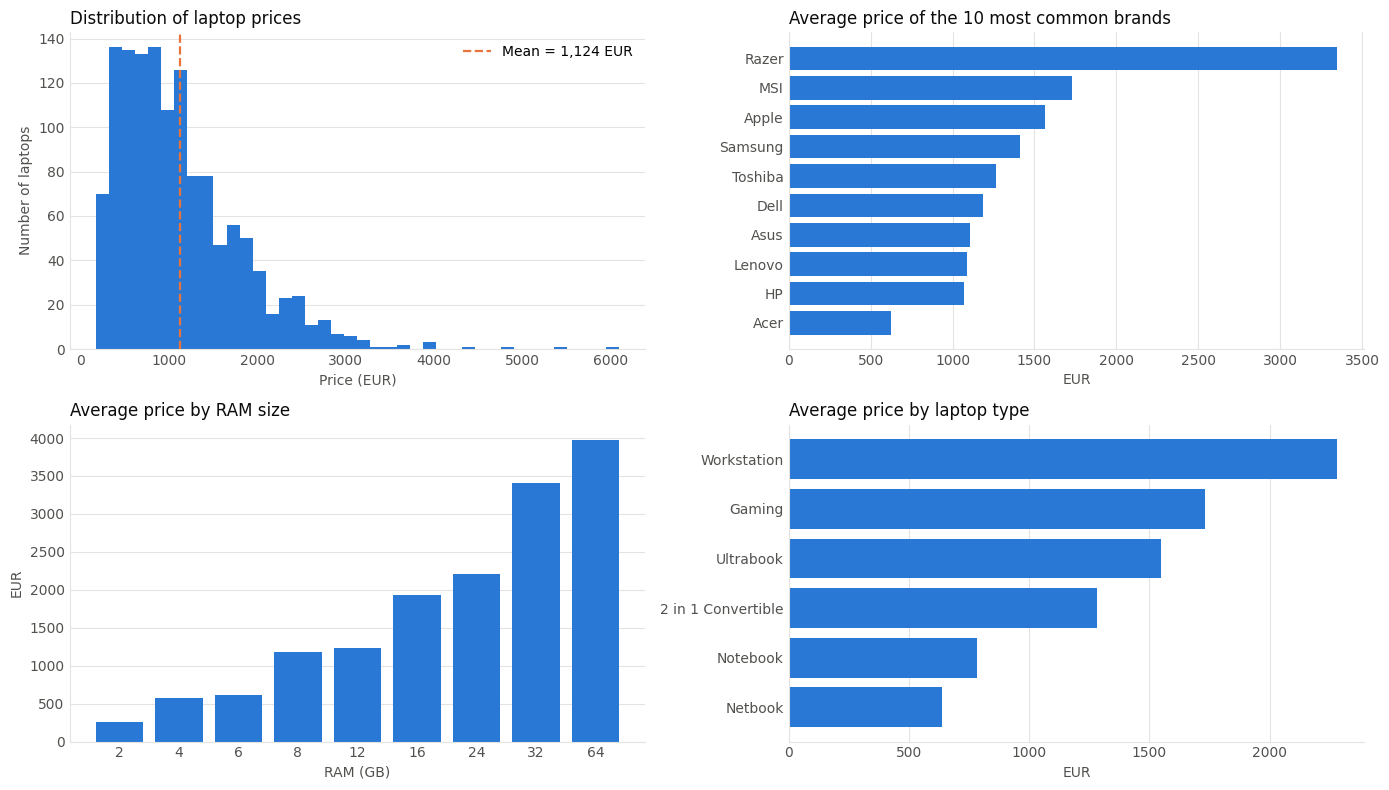

In [6]:
"""
Purpose of this section:
-------------------------
Draws four charts to see which specifications are related to price.
1. Distribution of laptop prices.
2. Average price of the 10 most common brands.
3. Average price for each RAM size.
4. Average price for each laptop type.
"""
BAR_COLOR, ACCENT = "#2a78d6", "#e8743b"
TEXT_COLOR, MUTED_TEXT, GRID_COLOR = "#0b0b0b", "#52514e", "#e4e3df"

def clean_axis(ax, grid_axis="y"):
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(GRID_COLOR)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.tick_params(colors=MUTED_TEXT, length=0)
    ax.grid(axis=grid_axis, color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].hist(df["Price_euros"], bins=40, color=BAR_COLOR)
axes[0, 0].axvline(df["Price_euros"].mean(), color=ACCENT, ls="--", lw=1.6, label=f"Mean = {df['Price_euros'].mean():,.0f} EUR")
axes[0, 0].set_title("Distribution of laptop prices", loc="left", color=TEXT_COLOR)
axes[0, 0].set_xlabel("Price (EUR)", color=MUTED_TEXT)
axes[0, 0].set_ylabel("Number of laptops", color=MUTED_TEXT)
axes[0, 0].legend(frameon=False)

top = df["Company"].value_counts().head(10).index
by_brand = df[df["Company"].isin(top)].groupby("Company")["Price_euros"].mean().sort_values()
axes[0, 1].barh(by_brand.index, by_brand.values, color=BAR_COLOR)
axes[0, 1].set_title("Average price of the 10 most common brands", loc="left", color=TEXT_COLOR)
axes[0, 1].set_xlabel("EUR", color=MUTED_TEXT)

by_ram = df.groupby("Ram_GB")["Price_euros"].mean()
axes[1, 0].bar(by_ram.index.astype(int).astype(str), by_ram.values, color=BAR_COLOR)
axes[1, 0].set_title("Average price by RAM size", loc="left", color=TEXT_COLOR)
axes[1, 0].set_xlabel("RAM (GB)", color=MUTED_TEXT)
axes[1, 0].set_ylabel("EUR", color=MUTED_TEXT)

by_type = df.groupby("TypeName")["Price_euros"].mean().sort_values()
axes[1, 1].barh(by_type.index, by_type.values, color=BAR_COLOR)
axes[1, 1].set_title("Average price by laptop type", loc="left", color=TEXT_COLOR)
axes[1, 1].set_xlabel("EUR", color=MUTED_TEXT)

for ax, g in zip(axes.ravel(), ["y", "x", "y", "x"]):
    clean_axis(ax, g)
plt.tight_layout()
plt.show()

**What the charts tell us**
1. **Prices are skewed:** about 77% of the laptops cost under 1,500 EUR, but a few premium models go above 4,000 EUR. These rare expensive laptops have a large influence on RMSE, so the models are trained on the **logarithm of the price** (Step 5), which makes the target more balanced.
2. **Specifications matter:** the average price rises steeply with RAM (about 575 EUR at 4 GB, 1,181 EUR at 8 GB, 1,937 EUR at 16 GB and 3,413 EUR at 32 GB) and with the laptop type (Netbook and Notebook are cheapest; Gaming and Workstation are the most expensive).
3. **Brand matters:** among the 10 most common brands, Razer, MSI and Apple are the most expensive on average, while Acer is by far the cheapest (about 627 EUR).
4. The relationships are **not simple straight lines** (doubling the RAM more than doubles the price), so non-linear algorithms should do better than a linear one.

<a id="step-4"></a>

### Step 4: Feature Extraction

<a id="step-4-1"></a>

#### Step 4.1: Create the Input Features and the Output

In [7]:
"""
Purpose of this section:
-------------------------
Separates the input (X) from the output (y) and lists which columns are
numeric and which are categorical (text labels).
"""
target = "Price_euros"

numeric_features = ["Inches", "Ram_GB", "Weight_kg", "ppi", "Cpu_GHz",
                    "SSD_GB", "HDD_GB", "Other_Storage_GB", "Touchscreen", "IPS"]
categorical_features = ["Company", "TypeName", "Cpu_Family", "Gpu_Brand", "OS_Group"]
feature_names = numeric_features + categorical_features

X = df[feature_names]
y = df[target]

print("Feature Vectors (first 8 rows):")
print("===============================\n")
print(X.head(8).to_string(index=False))
print(f"\nInput features (X): {X.shape[1]} columns  ({len(numeric_features)} numeric + {len(categorical_features)} categorical)")
print(f"Output (y)        : {target}")
print(f"Number of laptops : {len(X):,}")
print(f"Missing input values: {X.isnull().sum().sum()}")

Feature Vectors (first 8 rows):

 Inches  Ram_GB  Weight_kg     ppi  Cpu_GHz  SSD_GB  HDD_GB  Other_Storage_GB  Touchscreen  IPS Company  TypeName    Cpu_Family Gpu_Brand OS_Group
 13.300   8.000      1.370 226.983    2.300 128.000   0.000             0.000            0    1   Apple Ultrabook Intel Core i5     Intel    macOS
 13.300   8.000      1.340 127.678    1.800   0.000   0.000           128.000            0    0   Apple Ultrabook Intel Core i5     Intel    macOS
 15.600   8.000      1.860 141.212    2.500 256.000   0.000             0.000            0    0      HP  Notebook Intel Core i5     Intel    No OS
 15.400  16.000      1.830 220.535    2.700 512.000   0.000             0.000            0    1   Apple Ultrabook Intel Core i7       AMD    macOS
 13.300   8.000      1.370 226.983    3.100 256.000   0.000             0.000            0    1   Apple Ultrabook Intel Core i5     Intel    macOS
 15.600   4.000      2.100 100.455    3.000   0.000 500.000             0.000        

<a id="step-4-2"></a>

#### Step 4.2: Calculate a Simple Baseline

In [8]:
"""
Purpose of this section:
-------------------------
A useful model must beat the simplest possible guess: "every laptop costs
the average price". Its RMSE is a reference line for the results later.
(The baseline is calculated properly inside the cross validation in Step 6.4.)
"""
quick_baseline = np.sqrt(mean_squared_error(y, np.full(len(y), y.mean())))

print("Average-Price Guess (quick estimate):")
print("=====================================\n")
print(f"Average laptop price : {y.mean():,.2f} EUR")
print(f"Typical error if we always guess the average: {quick_baseline:,.2f} EUR")

Average-Price Guess (quick estimate):

Average laptop price : 1,123.69 EUR
Typical error if we always guess the average: 698.74 EUR


<a id="step-5"></a>

### Step 5: Build the Pre-processing Pipeline

The pipeline treats the two kinds of columns differently:

| Columns | Transformation | Why |
| --- | --- | --- |
| **Numeric** (10) | Fill missing values with the median, then **standard scaling** | KNN, SVR and Lasso are sensitive to scale: `HDD_GB` (up to 2048) would otherwise dominate `Ram_GB` (2-64) |
| **Categorical** (5) | **One-Hot Encoding** (rare labels with fewer than 10 laptops are merged into one "infrequent" group; unknown labels are ignored) | Algorithms need numbers; one-hot columns avoid giving brands a fake order |

The model is wrapped in **`TransformedTargetRegressor`** with `log1p` / `expm1`: the algorithm learns the **log of the price**, and its prediction is converted back to euros automatically. Every RMSE in this notebook is therefore in **euros**.

All steps are **inside** the pipeline, so in each cross-validation round they are fitted on the training folds only. This prevents data leakage.

In [9]:
"""
Purpose of this section:
-------------------------
Creates the pre-processing pipeline (ColumnTransformer). It is combined with
each algorithm in Step 6.4.
"""
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False),
     categorical_features),
])

def make_model(regressor):
    """pre-processing -> algorithm -> (prediction converted from log-price back to euros)"""
    return TransformedTargetRegressor(
        regressor=Pipeline([("preprocessor", preprocessor), ("regressor", regressor)]),
        func=np.log1p, inverse_func=np.expm1,
    )

print("Pre-processing Pipeline:")
print("========================\n")
print(preprocessor)

Pre-processing Pipeline:

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Inches', 'Ram_GB', 'Weight_kg', 'ppi',
                                  'Cpu_GHz', 'SSD_GB', 'HDD_GB',
                                  'Other_Storage_GB', 'Touchscreen', 'IPS']),
                                ('cat',
                                 OneHotEncoder(handle_unknown='infrequent_if_exist',
                                               min_frequency=10,
                                               sparse_output=False),
                                 ['Company', 'TypeName', 'Cpu_Family',
                                  'Gpu_Brand', 'OS_Group'])])


<a id="step-6"></a>

### Step 6: Execute the Training and Testing Phase (10-Fold Cross Validation)

**K-Fold Cross Validation** splits the data into **K = 10 folds**. In each of the 10 rounds the model is **trained on 9 folds** and **tested on the remaining fold**, so every laptop is used for testing exactly once. We report the **average RMSE** of the 10 rounds.

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

RMSE is in **euros**. **Lower RMSE = better model.**

<a id="step-6-1"></a>

#### Step 6.1: Define the 5 Regression Algorithms

| # | Algorithm | How it predicts the price |
| --- | --- | --- |
| 1 | **Lasso Regression** | A linear model with an **L1 penalty** that shrinks unimportant feature weights to exactly zero (automatic feature selection) |
| 2 | **K-Nearest Neighbors (KNN)** | Finds the 7 most similar laptops (by specifications) and averages their prices, closer neighbors count more |
| 3 | **Support Vector Regression (SVR)** | Fits a smooth non-linear curve using an **RBF kernel**, ignoring small errors inside a margin |
| 4 | **Gradient Boosting** | Builds 300 small trees one after another, each tree correcting the mistakes of the previous ones |
| 5 | **Hist Gradient Boosting** | A faster, histogram-based version of gradient boosting (the idea behind LightGBM) |

In [10]:
"""
Purpose of this section:
-------------------------
Creates the 5 regression algorithms. random_state=42 makes the results
reproducible.
"""
algorithms = {
    "Lasso Regression": Lasso(alpha=0.001, max_iter=10000),
    "K-Nearest Neighbors": KNeighborsRegressor(n_neighbors=7, weights="distance"),
    "Support Vector Regression": SVR(kernel="rbf", C=10.0, epsilon=0.05),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                   subsample=0.8, random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42),
}

print("Algorithms to Compare:")
print("======================\n")
for number, name in enumerate(algorithms, start=1):
    print(f"{number}. {name}")

Algorithms to Compare:

1. Lasso Regression
2. K-Nearest Neighbors
3. Support Vector Regression
4. Gradient Boosting
5. Hist Gradient Boosting


<a id="step-6-2"></a>

#### Step 6.2: Create the 10-Fold Splitter

Each laptop is an **independent row** (the price of one laptop does not depend on the previous row), so the rows are **shuffled** before splitting (`shuffle=True`). `random_state=42` gives the same folds every time, and the **same folds are used for all 5 algorithms**, which makes the comparison fair.

In [11]:
"""
Purpose of this section:
-------------------------
Creates the 10-fold splitter and stores the 10 (train, test) index pairs.
"""
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=42)
folds = list(kfold.split(X))

print(f"{K}-Fold Cross Validation created (shuffle=True, random_state=42)")

10-Fold Cross Validation created (shuffle=True, random_state=42)


<a id="step-6-3"></a>

#### Step 6.3: Inspect the Folds

In [12]:
"""
Purpose of this section:
-------------------------
Shows how many laptops are used for training and testing in each round,
and the average and maximum price inside each test fold.
"""
fold_info = []
for fold_number, (train_index, test_index) in enumerate(folds, start=1):
    fold_info.append({
        "Fold": fold_number,
        "Training Laptops": len(train_index),
        "Testing Laptops": len(test_index),
        "Avg Price in Test (EUR)": y.iloc[test_index].mean(),
        "Max Price in Test (EUR)": y.iloc[test_index].max(),
    })

print("Training and Testing Laptops in Each Fold:")
print("==========================================\n")
print(pd.DataFrame(fold_info).set_index("Fold"))

Training and Testing Laptops in Each Fold:

      Training Laptops  Testing Laptops  Avg Price in Test (EUR)  Max Price in Test (EUR)
Fold                                                                                     
1                 1172              131                1,113.187                6,099.000
2                 1172              131                1,091.567                4,899.000
3                 1172              131                1,267.931                3,975.000
4                 1173              130                1,082.686                3,299.000
5                 1173              130                1,132.896                3,890.000
6                 1173              130                1,052.399                3,588.800
7                 1173              130                1,028.360                3,100.000
8                 1173              130                1,163.985                5,499.000
9                 1173              130                1

<a id="step-6-4"></a>

#### Step 6.4: Run 10-Fold Cross Validation for All 5 Algorithms

For every algorithm and every fold we (1) make a **fresh copy** of the pipeline, (2) **train** it on the 9 training folds, (3) **predict** the test fold and (4) calculate **RMSE** and **R²**. A **baseline** that always predicts the training-fold average price is evaluated on the same folds. The `tqdm` progress bar shows the elapsed and remaining time.

In [13]:
"""
Purpose of this section:
-------------------------
Trains and tests every algorithm on every fold and stores the results.
"""
fold_rmse, fold_r2, training_time = {}, {}, {}
oof_predictions = {}        # out-of-fold predictions: every laptop predicted while it was in a test fold

# Baseline: always predict the average price of the training folds
baseline_rmses = []
for train_index, test_index in folds:
    dummy = DummyRegressor(strategy="mean").fit(X.iloc[train_index], y.iloc[train_index])
    baseline_rmses.append(np.sqrt(mean_squared_error(y.iloc[test_index], dummy.predict(X.iloc[test_index]))))
baseline_rmse = float(np.mean(baseline_rmses))

with tqdm(total=len(algorithms) * K, unit="fold") as progress_bar:
    for name, algorithm in algorithms.items():
        model = make_model(algorithm)

        rmses, r2s = [], []
        oof = np.zeros(len(X))
        start = time.time()
        for fold_number, (train_index, test_index) in enumerate(folds, start=1):
            progress_bar.set_description(f"{name}, fold {fold_number}/{K}")

            fold_model = clone(model)                                   # fresh, untrained copy
            fold_model.fit(X.iloc[train_index], y.iloc[train_index])    # train on 9 folds
            predictions = fold_model.predict(X.iloc[test_index])        # test on 1 fold

            rmses.append(np.sqrt(mean_squared_error(y.iloc[test_index], predictions)))
            r2s.append(r2_score(y.iloc[test_index], predictions))
            oof[test_index] = predictions
            progress_bar.update(1)

        training_time[name] = time.time() - start
        fold_rmse[name] = np.array(rmses)
        fold_r2[name] = np.array(r2s)
        oof_predictions[name] = oof
        tqdm.write(f"{name:<27} -> mean RMSE = {fold_rmse[name].mean():8.2f} EUR   ({training_time[name]:.1f} s)")

    progress_bar.set_description("Done")

print(f"\n{K}-fold cross validation completed for all {len(algorithms)} algorithms.")
print(f"Baseline (always the average price) mean RMSE = {baseline_rmse:.2f} EUR")

  0%|          | 0/50 [00:00<?, ?fold/s]

Lasso Regression, fold 1/10:   0%|          | 0/50 [00:00<?, ?fold/s]

Lasso Regression, fold 2/10:   2%|▏         | 1/50 [00:00<00:01, 42.39fold/s]

Lasso Regression, fold 3/10:   4%|▍         | 2/50 [00:00<00:01, 46.10fold/s]

Lasso Regression, fold 4/10:   6%|▌         | 3/50 [00:00<00:00, 48.33fold/s]

...

Hist Gradient Boosting, fold 10/10: 100%|██████████| 50/50 [00:13<00:00,  1.59fold/s]

Hist Gradient Boosting, fold 10/10: 100%|██████████| 50/50 [00:13<00:00,  1.59fold/s]

Done: 100%|██████████| 50/50 [00:13<00:00,  1.59fold/s]                              

Done: 100%|██████████| 50/50 [00:13<00:00,  3.75fold/s]

Hist Gradient Boosting      -> mean RMSE =   274.24 EUR   (6.9 s)

10-fold cross validation completed for all 5 algorithms.
Baseline (always the average price) mean RMSE = 697.24 EUR


<a id="step-7"></a>

### Step 7: Evaluate and Compare the Algorithms

<a id="step-7-1"></a>

#### Step 7.1: RMSE of Each Algorithm on Each Fold

In [14]:
"""
Purpose of this section:
-------------------------
Shows the RMSE of every algorithm on every fold. The lowest RMSE in each
row (the best algorithm on that fold) is highlighted in green.
"""
per_fold_table = pd.DataFrame(fold_rmse)
per_fold_table.index = [f"Fold {i}" for i in range(1, K + 1)]
per_fold_table.index.name = "Fold"

print("Number of Folds Won by Each Algorithm:")
print("======================================\n")
print(per_fold_table.idxmin(axis=1).value_counts().to_string())

(per_fold_table.style
    .format("{:.2f}")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Number of Folds Won by Each Algorithm:

Hist Gradient Boosting       7
Gradient Boosting            2
Support Vector Regression    1


,Lasso Regression,K-Nearest Neighbors,Support Vector Regression,Gradient Boosting,Hist Gradient Boosting
Fold,,,,,
Fold 1,355.52,425.96,361.70,288.85,325.37
Fold 2,341.86,330.40,333.13,323.72,304.84
Fold 3,835.95,361.64,364.39,317.54,316.51
Fold 4,414.69,267.07,242.03,235.03,218.14
Fold 5,330.80,305.62,273.33,253.82,217.88
Fold 6,349.81,266.72,290.41,252.83,223.33
Fold 7,374.53,327.74,308.34,262.63,280.35
Fold 8,353.84,352.89,326.17,269.50,255.89
Fold 9,496.96,456.02,371.35,402.68,350.82


<a id="step-7-2"></a>

#### Step 7.2: Summary Comparison Table

| Column | Meaning |
| --- | --- |
| **Mean RMSE** | Average RMSE over the 10 folds, the **main measure for ranking** (lower is better) |
| **Std RMSE** | Standard deviation over the folds; small = consistent |
| **Best / Worst Fold** | Lowest and highest fold RMSE |
| **Mean R²** | Share of the price variation explained (1.0 = perfect) |
| **Improvement over Baseline** | How much lower the RMSE is than always guessing the average price |
| **Time** | Total time to train and test across all 10 folds |

In [15]:
"""
Purpose of this section:
-------------------------
Summarises the 10-fold results of each algorithm in one table and ranks the
algorithms by mean RMSE (Rank 1 = best).
"""
summary = pd.DataFrame({
    "Mean RMSE (EUR)": per_fold_table.mean(),
    "Std RMSE (EUR)": per_fold_table.std(),
    "Best Fold RMSE (EUR)": per_fold_table.min(),
    "Worst Fold RMSE (EUR)": per_fold_table.max(),
    "Mean R²": pd.DataFrame(fold_r2).mean(),
    "Improvement over Baseline": (1 - per_fold_table.mean() / baseline_rmse) * 100,
    "Time (s)": pd.Series(training_time),
})
summary = summary.sort_values("Mean RMSE (EUR)")
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.index.name = "Algorithm"

print(f"Average laptop price: {y.mean():,.2f} EUR   |   Baseline RMSE: {baseline_rmse:,.2f} EUR\n")
(summary.style
    .format({"Mean RMSE (EUR)": "{:.2f}", "Std RMSE (EUR)": "{:.2f}", "Best Fold RMSE (EUR)": "{:.2f}",
             "Worst Fold RMSE (EUR)": "{:.2f}", "Mean R²": "{:.3f}",
             "Improvement over Baseline": "{:+.1f}%", "Time (s)": "{:.1f}"})
    .highlight_min(subset=["Mean RMSE (EUR)"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Average laptop price: 1,123.69 EUR   |   Baseline RMSE: 697.24 EUR



,Rank,Mean RMSE (EUR),Std RMSE (EUR),Best Fold RMSE (EUR),Worst Fold RMSE (EUR),Mean R²,Improvement over Baseline,Time (s)
Algorithm,,,,,,,,
Hist Gradient Boosting,1,274.24,48.44,217.88,350.82,0.841,+60.7%,6.9
Gradient Boosting,2,288.88,48.90,235.03,402.68,0.823,+58.6%,4.4
Support Vector Regression,3,310.10,50.46,230.19,371.35,0.799,+55.5%,1.6
K-Nearest Neighbors,4,339.74,62.31,266.72,456.02,0.758,+51.3%,0.2
Lasso Regression,5,420.19,154.11,330.80,835.95,0.604,+39.7%,0.2


<a id="step-7-3"></a>

#### Step 7.3: Visual Comparison

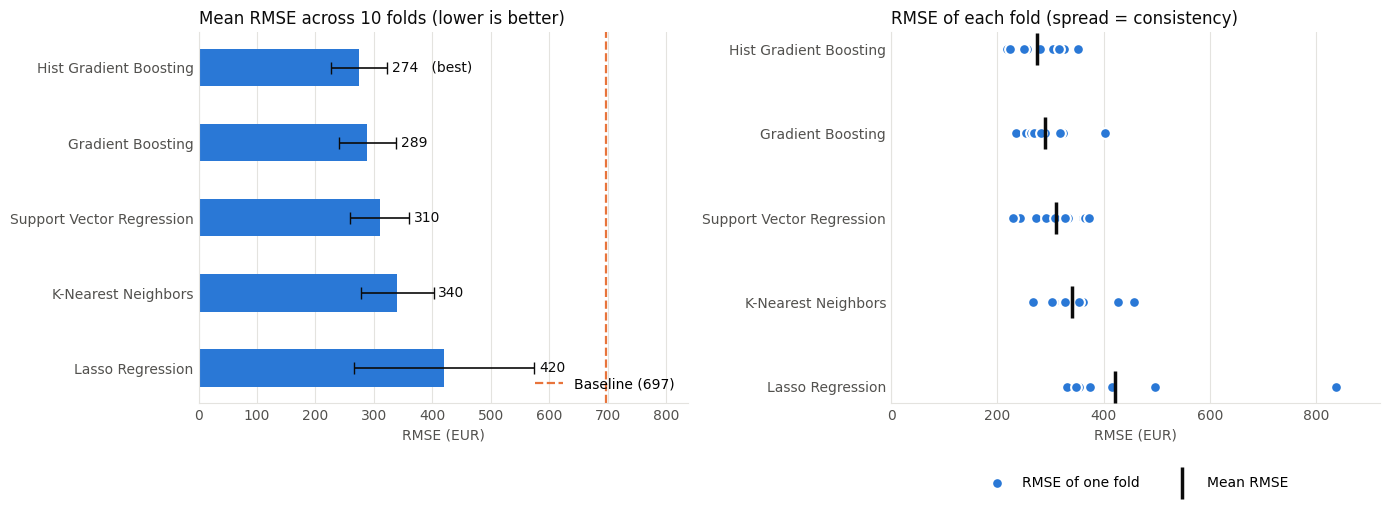

In [16]:
"""
Purpose of this section:
-------------------------
Chart 1: mean RMSE of each algorithm (+/- 1 standard deviation); the dashed
         line is the baseline.
Chart 2: RMSE of every individual fold as a dot (spread = consistency).
"""
order = summary.index.tolist()          # best algorithm first
positions = np.arange(len(order))
means = summary["Mean RMSE (EUR)"]
stds = summary["Std RMSE (EUR)"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

ax1.barh(positions, means, height=0.5, color=BAR_COLOR,
         xerr=stds, error_kw=dict(ecolor=TEXT_COLOR, elinewidth=1.2, capsize=4))
ax1.axvline(baseline_rmse, color=ACCENT, ls="--", lw=1.6, label=f"Baseline ({baseline_rmse:,.0f})")
for i, name in enumerate(order):
    label = f"{means[name]:.0f}" + ("   (best)" if i == 0 else "")
    ax1.text(means[name] + stds[name] + 8, i, label, va="center", color=TEXT_COLOR, fontsize=10)
ax1.set_yticks(positions, order, color=TEXT_COLOR)
ax1.invert_yaxis()
ax1.set_xlim(0, max((means + stds).max(), baseline_rmse) * 1.2)
clean_axis(ax1, grid_axis="x")
ax1.set_title("Mean RMSE across 10 folds (lower is better)", loc="left", color=TEXT_COLOR, fontsize=12)
ax1.set_xlabel("RMSE (EUR)", color=MUTED_TEXT)
ax1.legend(frameon=False, loc="lower right")

for i, name in enumerate(order):
    ax2.scatter(per_fold_table[name], np.full(K, i), s=60, color=BAR_COLOR, edgecolor="white",
                linewidth=1.5, zorder=3, label="RMSE of one fold" if i == 0 else None)
    ax2.scatter(means[name], i, marker="|", s=500, color=TEXT_COLOR, linewidth=2.5, zorder=4,
                label="Mean RMSE" if i == 0 else None)
ax2.set_yticks(positions, order, color=TEXT_COLOR)
ax2.invert_yaxis()
ax2.set_xlim(0, per_fold_table.values.max() * 1.1)
clean_axis(ax2, grid_axis="x")
ax2.set_title("RMSE of each fold (spread = consistency)", loc="left", color=TEXT_COLOR, fontsize=12)
ax2.set_xlabel("RMSE (EUR)", color=MUTED_TEXT)
ax2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)

plt.tight_layout()
plt.show()

<a id="step-7-4"></a>

#### Step 7.4: Actual vs Predicted Prices

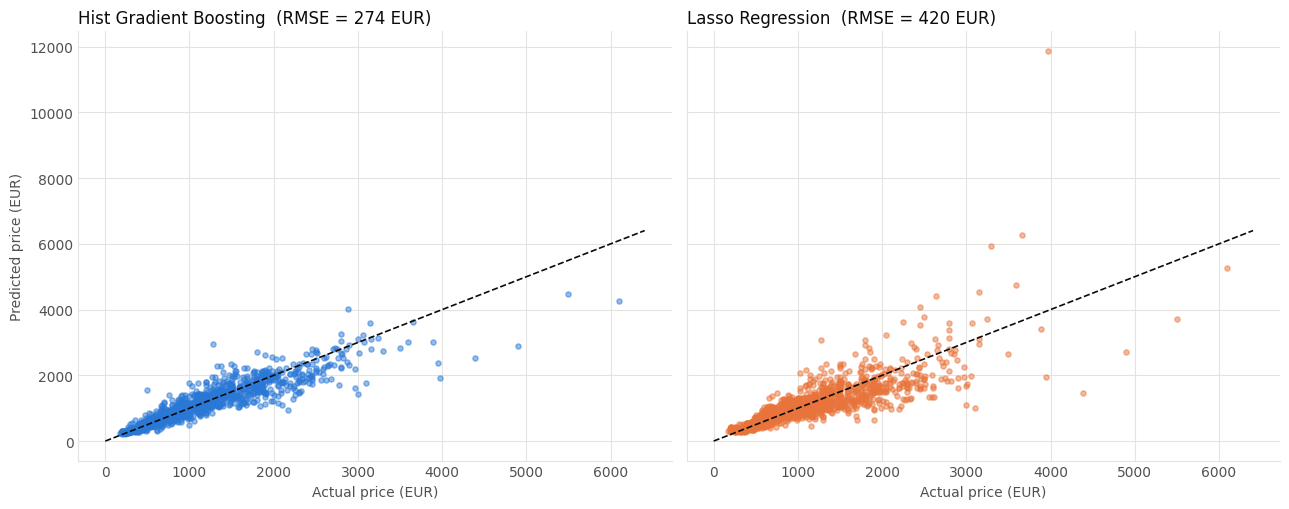

Hist Gradient Boosting: 63% of the laptops are predicted within +/- 15% of the real price


In [17]:
"""
Purpose of this section:
-------------------------
Scatter plots of actual price vs predicted price for the best and the worst
algorithm. Every dot is a laptop that was predicted while it was in a test
fold (the model had not seen it). Dots on the dashed diagonal = perfect.
"""
best_name, worst_name = order[0], order[-1]
limit = float(y.max()) * 1.05

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharex=True, sharey=True)
for ax, name, color in zip(axes, [best_name, worst_name], [BAR_COLOR, ACCENT]):
    ax.scatter(y, oof_predictions[name], s=14, alpha=0.5, color=color)
    ax.plot([0, limit], [0, limit], color=TEXT_COLOR, ls="--", lw=1.2)
    ax.set_title(f"{name}  (RMSE = {means[name]:.0f} EUR)", loc="left", color=TEXT_COLOR, fontsize=12)
    ax.set_xlabel("Actual price (EUR)", color=MUTED_TEXT)
    clean_axis(ax, grid_axis="both")
axes[0].set_ylabel("Predicted price (EUR)", color=MUTED_TEXT)
plt.tight_layout()
plt.show()

oof_best = oof_predictions[best_name]
share_within_15 = (np.abs(oof_best - y) / y <= 0.15).mean() * 100
print(f"{best_name}: {share_within_15:.0f}% of the laptops are predicted within +/- 15% of the real price")

<a id="step-7-5"></a>

#### Step 7.5: Observations

> The numbers below come from our run (`random_state=42`). With different library versions the numbers may differ slightly, but the pattern should stay the same.

1. **Hist Gradient Boosting is the best algorithm: mean RMSE about 274 EUR** (R² = 0.84). It has the lowest RMSE on **7 of the 10 folds**, followed by **Gradient Boosting (about 289 EUR, 2 folds)** and **Support Vector Regression (about 310 EUR, 1 fold)**. The gap between the top two (about 15 EUR) is smaller than the fold-to-fold standard deviation (about 48 EUR), so these two are close; Hist Gradient Boosting is preferred because it is ahead on most folds and has the highest R².
2. **All five algorithms beat the baseline.** Always guessing the average price gives an RMSE of about 697 EUR; the best model reduces this error by about **61%**, and even the weakest model (Lasso) reduces it by about 40%.
3. **Non-linear models win.** Lasso Regression is the weakest (about 420 EUR, R² = 0.60) because a straight-line model cannot capture how price jumps with RAM, SSD size and laptop type. Its **worst fold (Fold 3) has an RMSE of about 836 EUR**, far above the other models on the same fold (about 320-365 EUR): a linear model reacts badly to a few very expensive laptops. The two boosting models and SVR were much more stable across the folds.
4. **KNN is in the middle (about 340 EUR).** It averages the prices of the 7 most similar laptops, which works well for common configurations but poorly for unusual ones that have few similar neighbours.
5. **Training time is not a problem here.** With only 1,303 rows, every algorithm finishes all 10 folds in a few seconds; Lasso and KNN are fastest, the boosting models take the longest.
6. **Prediction quality in practice:** about **63% of the laptops are predicted within +/- 15% of the real price** (Step 7.4). The scatter plot shows that the model tends to **under-estimate the most expensive laptops**, because there are very few of them in the data.
7. **The remaining error is expected:** the data does not contain the exact CPU model or generation, the GPU model, the release date or special features, and shops price the same specifications differently.

<a id="step-8"></a>

### Step 8: Train and Save the Final Model

<a id="step-8-1"></a>

#### Step 8.1: Select the Best Algorithm

In [18]:
"""
Purpose of this section:
-------------------------
Cross validation is used to CHOOSE an algorithm, not to produce the final
model. We pick the algorithm with the lowest mean RMSE (Rank 1).
"""
best_algorithm_name = summary.index[0]
best_mean_rmse = summary.loc[best_algorithm_name, "Mean RMSE (EUR)"]
best_std_rmse = summary.loc[best_algorithm_name, "Std RMSE (EUR)"]

print("Best Algorithm:")
print("===============\n")
print(f"Algorithm     : {best_algorithm_name}")
print(f"Expected RMSE : {best_mean_rmse:,.2f} EUR (+/- {best_std_rmse:,.2f} EUR)")

Best Algorithm:

Algorithm     : Hist Gradient Boosting
Expected RMSE : 274.24 EUR (+/- 48.44 EUR)


<a id="step-8-2"></a>

#### Step 8.2: Train the Best Algorithm on All the Data

In [19]:
"""
Purpose of this section:
-------------------------
Trains the best algorithm on ALL 1,303 laptops. No separate test set is
needed: the cross-validation RMSE from Step 7 is our estimate of how well it
will perform on new laptops.
"""
final_model = make_model(clone(algorithms[best_algorithm_name]))
final_model.fit(X, y)

print(f"Final {best_algorithm_name} model trained on {len(X):,} laptops")

Final Hist Gradient Boosting model trained on 1,303 laptops


<a id="step-8-3"></a>

#### Step 8.3: Save the Trained Model

In [20]:
"""
Purpose of this section:
-------------------------
Saves the trained pipeline together with the information the web app needs
(feature order, the choices for the drop-down lists, CV results) in a .pkl
file. Also writes requirements.txt with the EXACT library versions of this run;
the web app must use the same versions, otherwise the .pkl may not load.
"""
MODEL_FILE = "laptop_price_model.pkl"
DOWNLOAD_FILES = False      # set to True in Colab to download both files

model_package = {
    "model": final_model,
    "algorithm": best_algorithm_name,
    "feature_names": feature_names,
    "cv_rmse_mean": float(best_mean_rmse),
    "cv_rmse_std": float(best_std_rmse),
    "baseline_rmse": float(baseline_rmse),
    "options": {col: sorted(df[col].unique().tolist()) for col in categorical_features},
    "ranges": {col: [float(df[col].min()), float(df[col].max()), float(df[col].median())] for col in numeric_features},
    "cv_summary": summary[["Rank", "Mean RMSE (EUR)", "Std RMSE (EUR)", "Mean R²"]].reset_index().to_dict("records"),
}

with open(MODEL_FILE, "wb") as f:           # 'wb' = write in binary mode
    pickle.dump(model_package, f)
print(f"Saved: {MODEL_FILE} ({os.path.getsize(MODEL_FILE) / 1e6:.2f} MB)")

requirements = f"""streamlit
numpy=={np.__version__}
pandas=={pd.__version__}
scikit-learn=={sklearn.__version__}
"""
with open("requirements.txt", "w") as f:
    f.write(requirements)
print("Saved: requirements.txt\n")
print(requirements)

if IN_COLAB and DOWNLOAD_FILES:
    files.download(MODEL_FILE)
    files.download("requirements.txt")

Saved: laptop_price_model.pkl (1.08 MB)
Saved: requirements.txt

streamlit
numpy==2.4.4
pandas==3.0.2
scikit-learn==1.8.0



<a id="step-9"></a>

### Step 9: Execute the Application Phase

<a id="step-9-1"></a>

#### Step 9.1: Take Input from User

A demo laptop (a mid-range 15.6" Dell notebook) is pre-filled so the notebook runs from top to bottom. To enter your own laptop interactively, replace a demo value with an `input()` line, for example:
```python
ram_gb = float(input("RAM in GB: "))
company = input("Brand (Dell, HP, Lenovo, ...): ")
```

In [21]:
"""
Purpose of this section:
-------------------------
Takes the specifications of a NEW (unseen) laptop. Edit the values to try your own.
"""
company = "Dell"
type_name = "Notebook"
inches = 15.6
ram_gb = 8
weight_kg = 2.2
screen_width, screen_height = 1920, 1080
touchscreen = 0
ips = 1
cpu_family_in = "Intel Core i5"
cpu_ghz = 2.5
ssd_gb = 256
hdd_gb = 1000
other_storage_gb = 0
gpu_brand = "Nvidia"
os_group = "Windows"

print(f"{company} {type_name}, {inches}\" screen ({screen_width}x{screen_height}, IPS={ips}, touch={touchscreen})")
print(f"{cpu_family_in} @ {cpu_ghz} GHz | {ram_gb} GB RAM | {ssd_gb} GB SSD + {hdd_gb} GB HDD")
print(f"GPU: {gpu_brand} | OS: {os_group} | Weight: {weight_kg} kg")

Dell Notebook, 15.6" screen (1920x1080, IPS=1, touch=0)
Intel Core i5 @ 2.5 GHz | 8 GB RAM | 256 GB SSD + 1000 GB HDD
GPU: Nvidia | OS: Windows | Weight: 2.2 kg


<a id="step-9-2"></a>

#### Step 9.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [22]:
"""
Purpose of this section:
-------------------------
Puts the user's input into a one-row DataFrame with exactly the same columns,
in the same order, as the training data. No manual scaling or encoding is
needed: the saved pipeline does it automatically.
"""
ppi = float(np.sqrt(screen_width ** 2 + screen_height ** 2) / inches)

user_input = pd.DataFrame([{
    "Inches": inches, "Ram_GB": ram_gb, "Weight_kg": weight_kg, "ppi": ppi, "Cpu_GHz": cpu_ghz,
    "SSD_GB": ssd_gb, "HDD_GB": hdd_gb, "Other_Storage_GB": other_storage_gb,
    "Touchscreen": touchscreen, "IPS": ips,
    "Company": company, "TypeName": type_name, "Cpu_Family": cpu_family_in,
    "Gpu_Brand": gpu_brand, "OS_Group": os_group,
}])[feature_names]

print("User Input Feature Vector:")
print("==========================\n")
print(user_input.T.rename(columns={0: "value"}))

User Input Feature Vector:

                          value
Inches                   15.600
Ram_GB                        8
Weight_kg                 2.200
ppi                     141.212
Cpu_GHz                   2.500
SSD_GB                      256
HDD_GB                     1000
Other_Storage_GB              0
Touchscreen                   0
IPS                           1
Company                    Dell
TypeName               Notebook
Cpu_Family        Intel Core i5
Gpu_Brand                Nvidia
OS_Group                Windows


<a id="step-9-3"></a>

#### Step 9.3: Load the Saved Model

In [23]:
"""
Purpose of this section:
-------------------------
Loads the saved model again, as the web app does.
"""
with open(MODEL_FILE, "rb") as f:           # 'rb' = read in binary mode
    loaded = pickle.load(f)
model = loaded["model"]
print(f"Model loaded from {MODEL_FILE}: {loaded['algorithm']}")

Model loaded from laptop_price_model.pkl: Hist Gradient Boosting


<a id="step-9-4"></a>

#### Step 9.4: Model Prediction

<a id="step-9-4-1"></a>

#### Step 9.4.1: Apply Model on the Feature Vector of Unseen Instance and Return Prediction to the User

In [24]:
"""
Purpose of this section:
-------------------------
Predicts the price of the laptop and shows the result together with the
typical error of the model.
"""
predicted_price = float(model.predict(user_input)[0])
rmse = loaded["cv_rmse_mean"]

pretty_table = PrettyTable()
pretty_table.field_names = ["** Laptop **", "** Predicted Price **", "** Likely Range **"]
pretty_table.add_row([f"{company} {type_name} {inches}\"",
                      f"{predicted_price:,.0f} EUR",
                      f"{max(predicted_price - rmse, 0):,.0f} - {predicted_price + rmse:,.0f} EUR"])
print(pretty_table)

+---------------------+-----------------------+--------------------+
|     ** Laptop **    | ** Predicted Price ** | ** Likely Range ** |
+---------------------+-----------------------+--------------------+
| Dell Notebook 15.6" |       1,097 EUR       |  823 - 1,372 EUR   |
+---------------------+-----------------------+--------------------+


<a id="step-10"></a>

### Step 10: Execute the Feedback Phase

<a id="step-10-1"></a>

#### Step 10.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [25]:
"""
Purpose of this section:
-------------------------
Example feedback from people who reviewed the model's price estimates
(illustrative cases written for this assignment).
"""
example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Laptop Retailer)", "Buyer", "Domain Expert (Laptop Retailer)"],
    "Case": [
        "Mid-range 15.6\" Windows notebook, 8 GB RAM, SSD -> estimate close to shop prices",
        "High-end gaming laptop with 32 GB RAM -> estimate was lower than the shop price",
        "Prices in the data are in euros from one time period",
    ],
    "Feedback": [
        "Realistic for common models; the model is most reliable in the 500-1500 EUR range.",
        "Very expensive laptops are rare in the data, so the model under-estimates them.",
        "Laptop prices fall quickly as new models arrive; the model needs fresh data to stay accurate.",
    ],
})
print(example_feedback.to_string(index=False))

                       Reviewer                                                                             Case                                                                                      Feedback
Domain Expert (Laptop Retailer) Mid-range 15.6" Windows notebook, 8 GB RAM, SSD -> estimate close to shop prices            Realistic for common models; the model is most reliable in the 500-1500 EUR range.
                          Buyer  High-end gaming laptop with 32 GB RAM -> estimate was lower than the shop price               Very expensive laptops are rare in the data, so the model under-estimates them.
Domain Expert (Laptop Retailer)                             Prices in the data are in euros from one time period Laptop prices fall quickly as new models arrive; the model needs fresh data to stay accurate.


<a id="step-10-2"></a>

#### Step 10.2: Make a List of Potential Improvements

In [26]:
"""
Purpose of this section:
-------------------------
Improvements identified from the feedback above.
"""
improvements = [
    "Collect more recent data, and more high-end and gaming laptops, so expensive models are predicted better",
    "Add the CPU generation / model number (for example i5-7200U vs i5-1135G7) and the GPU model as features",
    "Tune the hyper-parameters of the best algorithm with RandomizedSearchCV inside the cross validation",
    "Add the year of release, because older laptops are cheaper",
    "Add a Pakistani-rupee price option using the current exchange rate in the web app",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Collect more recent data, and more high-end and gaming laptops, so expensive models are predicted better
2. Add the CPU generation / model number (for example i5-7200U vs i5-1135G7) and the GPU model as features
3. Tune the hyper-parameters of the best algorithm with RandomizedSearchCV inside the cross validation
4. Add the year of release, because older laptops are cheaper
5. Add a Pakistani-rupee price option using the current exchange rate in the web app


<a id="step-10-3"></a>

#### Step 10.3: Improve the Model Based on Feedback

In [27]:
"""
Purpose of this section:
-------------------------
In a real deployment the next version would add the improvements above,
re-run Steps 6-7 and replace the deployed model only if the cross-validation
RMSE improves.
"""
print("Next version: add CPU generation and GPU model features, collect newer data, tune the best "
      f"algorithm, then re-run Steps 6-7 and replace {MODEL_FILE} only if the mean RMSE drops below "
      f"{best_mean_rmse:,.0f} EUR.")

Next version: add CPU generation and GPU model features, collect newer data, tune the best algorithm, then re-run Steps 6-7 and replace laptop_price_model.pkl only if the mean RMSE drops below 274 EUR.


<a id="step-11"></a>

## Step 11: Deploy Your Model as a Public Web App

So far only *you* can use the model, and only while the notebook is open. This step turns it into a **website** that anyone can open in a browser. Live app: _add your Streamlit link here_

<a id="step-11-1"></a>

#### Step 11.1: Why Deploy a Model?
A model that stays inside a notebook helps nobody except its author. A small web app lets non-technical users (a buyer, a shop owner) get a price estimate without installing anything.

<a id="step-11-2"></a>

#### Step 11.2: Create a GitHub Account and Repository
1. Sign up (free) at **https://github.com**.
2. Click **+ -> New repository**, give it a name such as `laptop-price-predictor`, keep it **Public** and create it.
3. Upload `app.py`, `requirements.txt` and `laptop_price_model.pkl` (**Add file -> Upload files**).

<a id="step-11-3"></a>

#### Step 11.3: Write a Simple Web App
`app.py` is a small **Streamlit** script. It:
1. Loads `laptop_price_model.pkl` (the pipeline already contains the imputer, scaler and encoder, so no manual pre-processing is needed).
2. Shows drop-downs and sliders for brand, type, screen, CPU, RAM, storage, GPU and operating system.
3. Converts the screen resolution and size into **ppi** and builds the feature row in exactly the same column order as `feature_names`.
4. Calls `model.predict(...)` when the button is clicked and shows the price and its likely range.

`requirements.txt` (written automatically in Step 8.3) must be in the same folder, so Streamlit installs the same library versions that were used for training.

<a id="step-11-4"></a>

#### Step 11.4: Create a Streamlit Community Cloud Account
Go to **https://share.streamlit.io** and choose **Sign in with GitHub** (free for public apps).

<a id="step-11-5"></a>

#### Step 11.5: Deploy Your App
1. Click **Create app** (or **New app**) and pick your repository and branch.
2. Set the main file path to `app.py`.
3. Click **Deploy**. After a minute or two the app is online at a link like `https://<your-app-name>.streamlit.app`.
4. Copy that link into the first cell of this notebook and into `README.txt`.

To test the app on your own computer first, run `streamlit run app.py` in the project folder.

<a id="conclusion"></a>

## Conclusion
Five regression algorithms (Lasso Regression, K-Nearest Neighbors, Support Vector Regression, Gradient Boosting and Hist Gradient Boosting) were compared on the Laptop Price dataset (1,303 laptops) using **10-fold cross validation** and **RMSE** (Step 7).

- **Hist Gradient Boosting** predicts laptop prices best, with a mean RMSE of about **274 EUR** (R² = 0.84), about **61% better** than always guessing the average price (about 697 EUR). It was trained on all the data, saved, and deployed as a Streamlit web app.
- **Gradient Boosting** and **Support Vector Regression** were close behind, **KNN** was in the middle, and **Lasso Regression** was weakest because the link between specifications and price is not linear.
- The raw data was mostly **text** (`"256GB SSD + 1TB HDD"`, `"Intel Core i5 7200U 2.5GHz"`), so converting it into numeric features such as RAM, SSD/HDD size, CPU family, CPU speed and screen sharpness (ppi) was an important part of the result.
- The target was modelled on a **log scale** so that the rare, very expensive laptops do not dominate the training.
- Main limitation: very expensive laptops are rare in the data and are under-estimated. More recent data, CPU generation and GPU model would be the first improvements (Step 10.2).